<a href="https://colab.research.google.com/github/joetecheamal2673/Assignments/blob/main/Assignment_4_Data_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#1). Loading the Taxis Dataset using the following code -
import seaborn as sns

df = sns.load_dataset("taxis")

df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [ ]:
#2).Handling Missing Values -
import pandas as pd
import seaborn as sns


df = sns.load_dataset("taxis")


print("Missing Values in Each Column:")
print(df.isnull().sum())


missing_columns = df.columns[df.isnull().any()]

print("\nColumns with Missing Values:")
print(missing_columns)


print("\nMissing Value Summary:")
print(df.isnull().sum()[df.isnull().sum() > 0])



numerical_columns = df.select_dtypes(include="number").columns
categorical_columns = df.select_dtypes(include=["object", "category"]).columns


for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

critical_columns = ["pickup", "dropoff", "distance"]

df.dropna(subset=critical_columns, inplace=True)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
df.head()

Missing Values in Each Column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with Missing Values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')

Missing Value Summary:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Cleaned Dataset

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


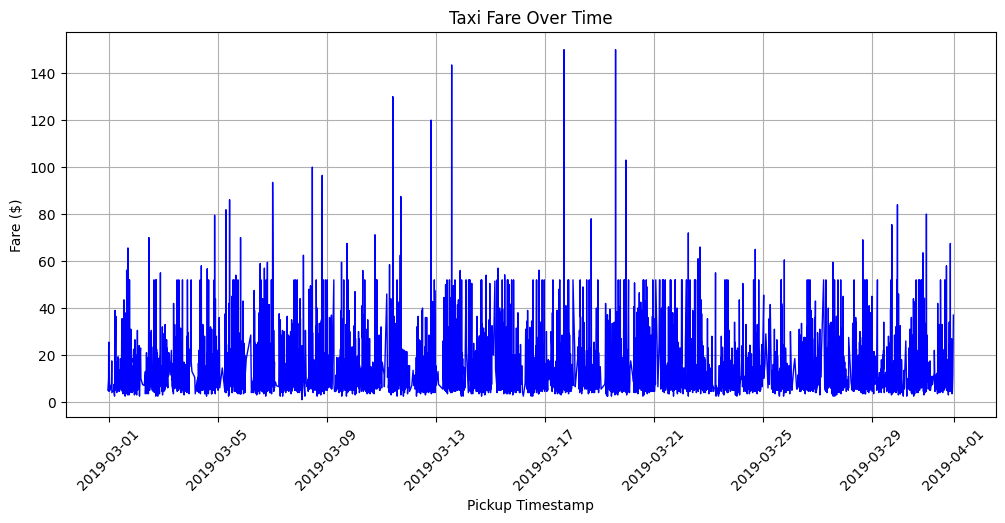

In [ ]:
#1.Line Chart – Fare Over Time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df["pickup"] = pd.to_datetime(df["pickup"])

df = df.sort_values("pickup")

plt.figure(figsize=(12, 5))

plt.plot(df["pickup"], df["fare"], color="blue", linewidth=1)

plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.grid(True)

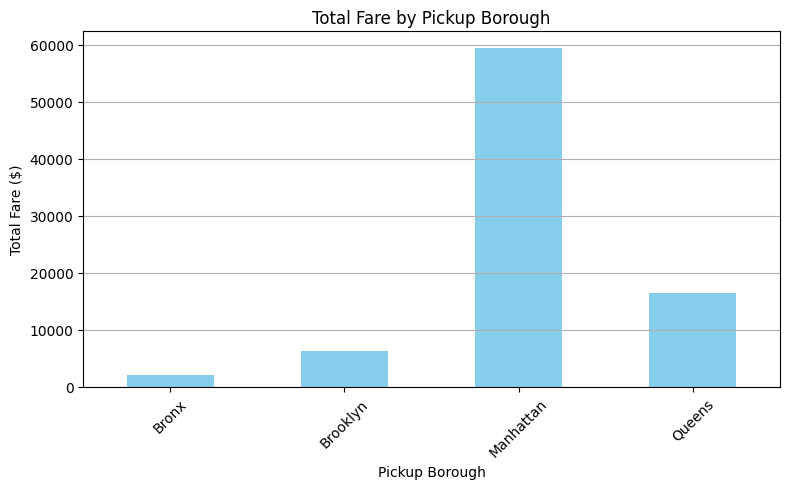

In [ ]:
#2.Bar Chart – Total Fare by Pickup Borough

borough_fare = df.groupby("pickup_borough", observed=True)["fare"].sum()

borough_fare.plot(kind="bar", figsize=(8, 5), color="skyblue")

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

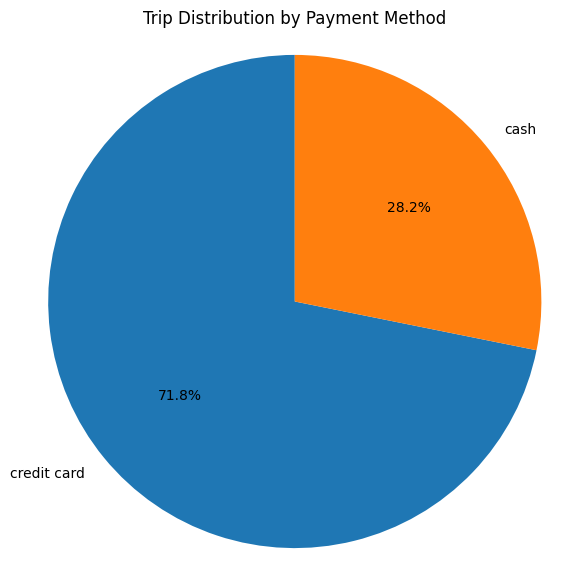

In [ ]:
#3.Pie Chart – Trip Distribution by Payment Method
payment_counts = df["payment"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Trip Distribution by Payment Method")
plt.axis("equal")

plt.show()

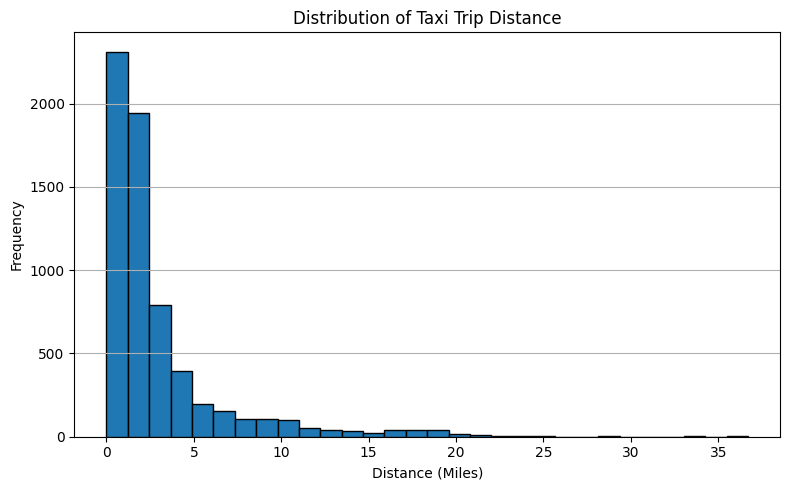

In [ ]:
#4.Histogram – Distribution of Trip Distance
plt.figure(figsize=(8, 5))

plt.hist(df["distance"], bins=30, edgecolor="black")

plt.title("Distribution of Taxi Trip Distance")
plt.xlabel("Distance (Miles)")
plt.ylabel("Frequency")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

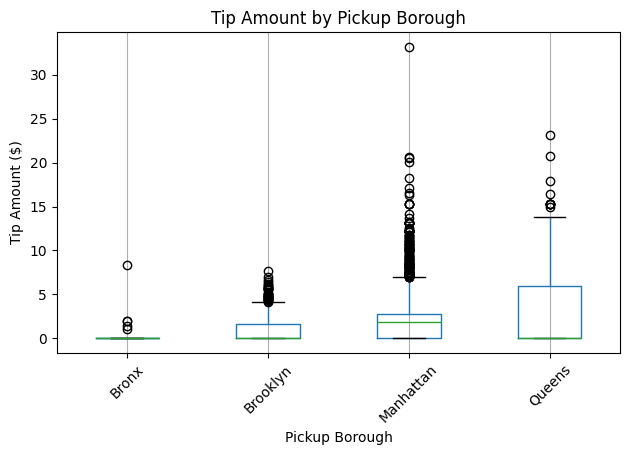

In [ ]:
#5.Box Plot – Tip Amount by Pickup Borough
plt.figure(figsize=(9, 5))

df.boxplot(column="tip", by="pickup_borough")

plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

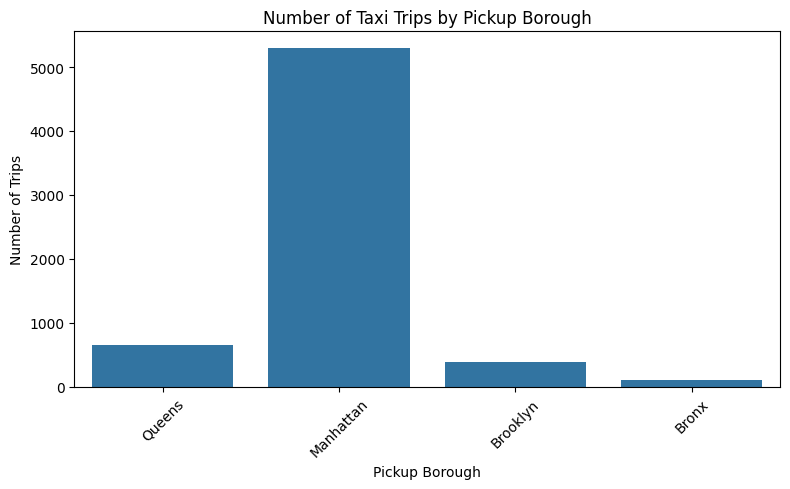

In [ ]:
# 6.Count Plot – Number of Trips by Pickup Borough
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Taxi Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

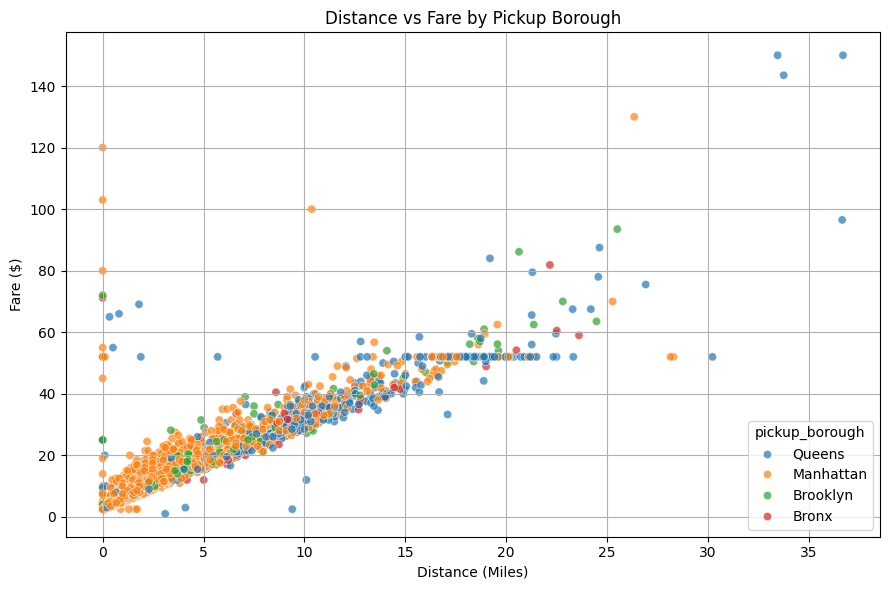

In [ ]:
#7. Scatter Plot – Distance vs Fare

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.7
)

plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (Miles)")
plt.ylabel("Fare ($)")
plt.grid(True)

plt.tight_layout()
plt.show()

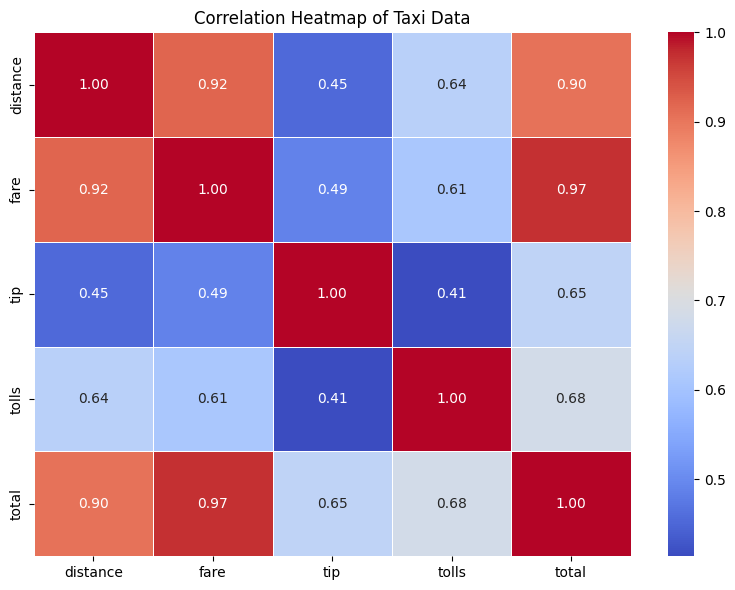

In [ ]:
#8.Heatmap – Correlation Between Numerical Variables

numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Data")

plt.tight_layout()
plt.show()

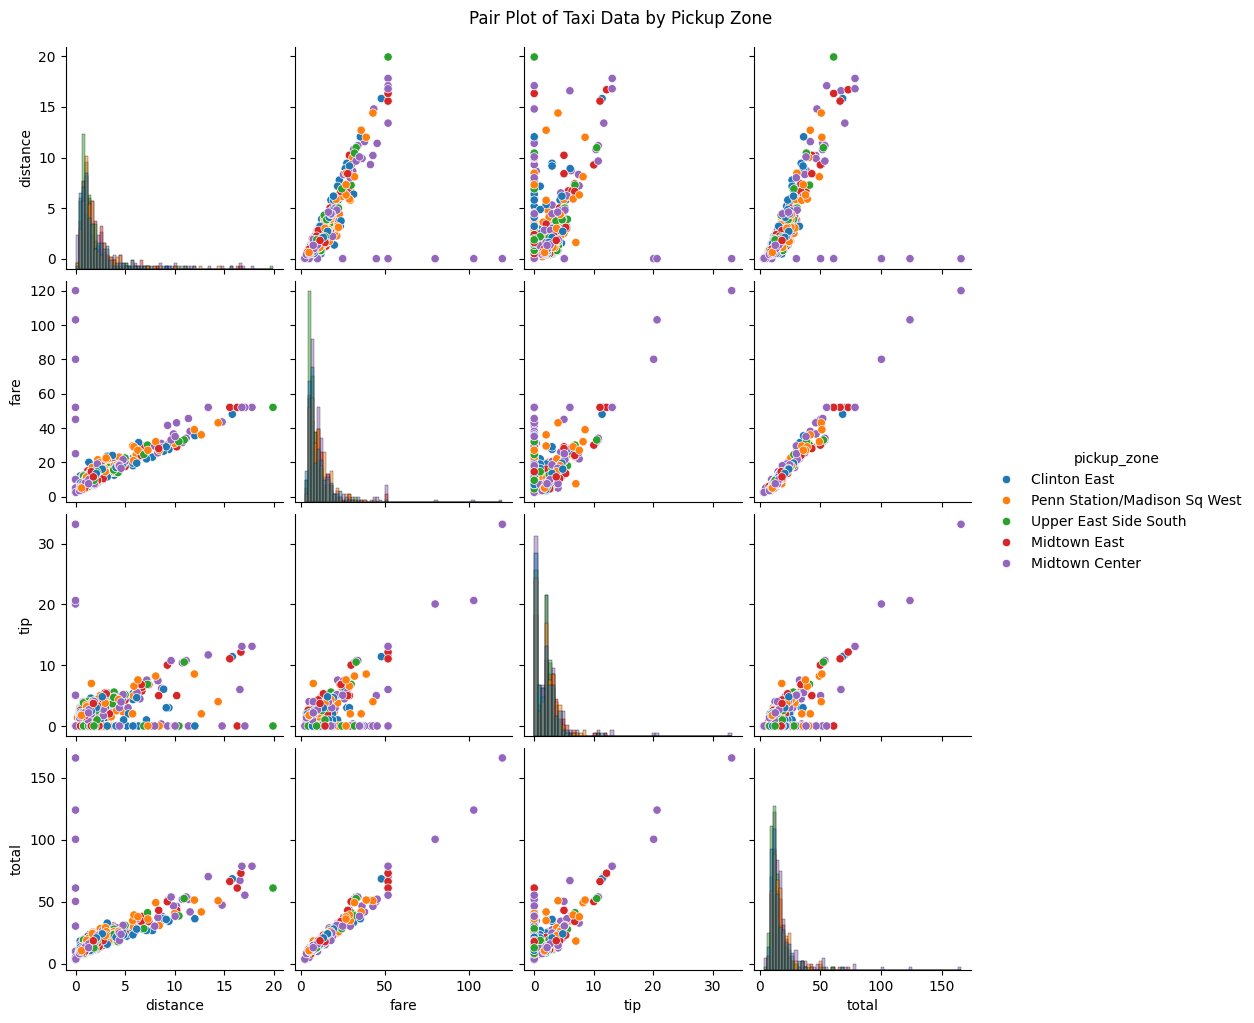

In [ ]:
#9. Pair Plot – Pairwise Relationships

pair_data = df[["distance", "fare", "tip", "total", "pickup_zone"]].dropna()


top_zones = pair_data["pickup_zone"].value_counts().head(5).index

pair_data = pair_data[pair_data["pickup_zone"].isin(top_zones)]

pair_data = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Taxi Data by Pickup Zone", y=1.02)

plt.show()

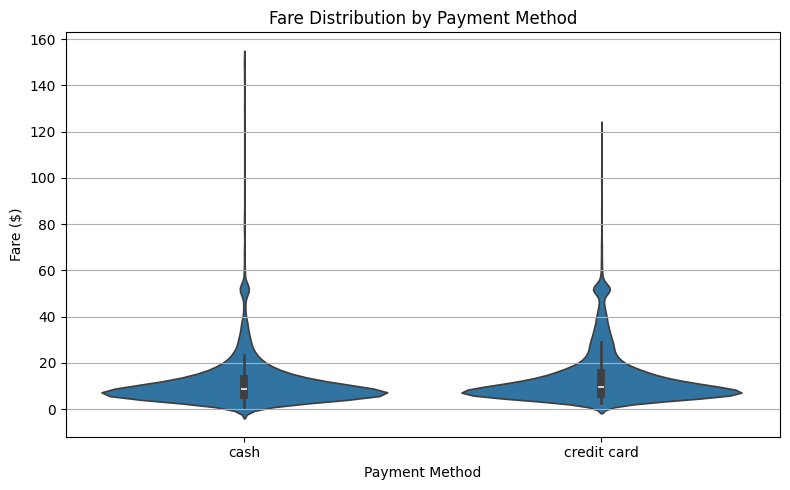

In [ ]:
#10. Violin Plot – Fare Distribution by Payment Method

plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.grid(axis="y")

plt.tight_layout()
plt.show()